# 01 : Exploration des données SEC (EDA qualité)

**Objectif du projet :** prédire l'évolution du bilan d'une entreprise à l'année suivante (t → t+1)
pour en déduire un score de solvabilité et de liquidité, comme aide à la décision pour une banque.

**Objectif de ce notebook :** vérifier la qualité des données brutes avant de construire la table de modélisation,
et en déduire des **règles de nettoyage justifiées par les données**.

**Données :** SEC EDGAR - Company Facts (XBRL, US-GAAP), rapports annuels 10-K et 10-K/A, montants en USD,
25 postes du bilan. Table longue produite par `src/ingest.py` : une ligne = une valeur déclarée.

| Colonne | Signification |
|---|---|
| `cik` | identifiant de l'entreprise à la SEC |
| `concept` | poste comptable US-GAAP (ex. `Assets`) |
| `val` | montant en USD |
| `end` | date du bilan (date de la valeur) |
| `filed` | date de dépôt du rapport |
| `form` | 10-K (annuel) ou 10-K/A (annuel corrigé) |
| `fy`, `fp` | exercice et période **du rapport** (pas de la valeur) |
| `accn` | identifiant unique du rapport |

In [1]:
import sys
print(sys.executable)

e:\DSI\balance-sheet-scoring\.venv\Scripts\python.exe


## 1. Chargement et vue d'ensemble

In [2]:
#chargement
import pandas as pd
df = pd.read_parquet("../data/interim/facts_long")
print(df.shape)
df.head()

(3024124, 9)


,cik,concept,val,end,filed,form,fy,fp,accn
0,0000001750,AccountsPayableCurrent,114906000.0,2010-05-31,2011-07-13,10-K,2011,FY,0001047469-11-006302
1,0000001750,AccountsPayableCurrent,185096000.0,2011-05-31,2011-07-13,10-K,2011,FY,0001047469-11-006302
2,0000001750,AccountsPayableCurrent,185096000.0,2011-05-31,2012-07-19,10-K,2012,FY,0001047469-12-007300
3,0000001750,AccountsPayableCurrent,201405000.0,2012-05-31,2012-07-19,10-K,2012,FY,0001047469-12-007300
4,0000001750,AccountsPayableCurrent,201400000.0,2012-05-31,2013-07-26,10-K,2013,FY,0001047469-13-007797


In [3]:
df["concept"].unique()

<ArrowStringArray>
[                                       'AccountsPayableCurrent',
                                  'AccountsReceivableNetCurrent',
                                     'AccruedLiabilitiesCurrent',
               'AccumulatedOtherComprehensiveIncomeLossNetOfTax',
                                                        'Assets',
                                                 'AssetsCurrent',
                                              'AssetsNoncurrent',
                         'CashAndCashEquivalentsAtCarryingValue',
                                              'CommonStockValue',
                                                   'DebtCurrent',
                                                      'Goodwill',
                          'IntangibleAssetsNetExcludingGoodwill',
                                                  'InventoryNet',
                              'LiabilitiesAndStockholdersEquity',
                                            'LiabilitiesC

In [5]:
#vue d'ensemble
print("Entreprises:", df["cik"].nunique())
print("Periode:", df["end"].min(), "→", df["end"].max())
print(df["form"].value_counts())
df["concept"].value_counts()

Entreprises: 14081
Periode: 1927-02-17 00:00:00 → 2201-10-31 00:00:00
form
10-K      2892235
10-K/A     131889
Name: count, dtype: int64


concept
StockholdersEquity                                               286324
CashAndCashEquivalentsAtCarryingValue                            258418
Assets                                                           209093
LiabilitiesAndStockholdersEquity                                 197711
RetainedEarningsAccumulatedDeficit                               183355
Liabilities                                                      161883
CommonStockValue                                                 161318
LiabilitiesCurrent                                               155766
AssetsCurrent                                                    155586
PropertyPlantAndEquipmentNet                                     151854
AccumulatedOtherComprehensiveIncomeLossNetOfTax                  128247
Goodwill                                                         119588
AccountsPayableCurrent                                           115509
CashCashEquivalentsRestrictedCashAndRestrictedCashEquiva

**Constat :**
- 3 024 124 valeurs, 14 081 entreprises, 25 postes ; 10-K/A = 4,4 % des lignes.
- Période **1927 → 2201** : dates impossibles (XBRL n'existe que depuis 2009) → erreurs de saisie à filtrer.
- `StockholdersEquity` et `Cash` ont **plus de lignes que `Assets`** : ils apparaissent aussi dans d'autres tableaux
  du 10-K (variation des capitaux propres, flux de trésorerie), sur 3 ans.
- `Liabilities` moins renseigné que `Assets` → reconstruction possible par l'identité comptable
  (Passifs = Actifs − Capitaux propres).

## 2. Contrôle des dates : écart entre date du bilan (`end`) et date de dépôt (`filed`)

In [6]:
ecart = (df["filed"] - df["end"]).dt.days
print("end après filed :", (ecart < 0).sum())
print("end > 3 ans avant filed :", (ecart > 3*365).sum())
df[ecart < 0].head()

end après filed : 122
end > 3 ans avant filed : 106716


,cik,concept,val,end,filed,form,fy,fp,accn
48749,0000016058,Goodwill,3.336079e+09,2019-09-30,2019-08-21,10-K,2019,FY,0001564590-19-032721
270525,0000096699,RetainedEarningsAccumulatedDeficit,-2.733000e+06,2019-09-29,2019-06-24,10-K,2018,FY,0001171843-19-004124
298678,0000104169,CashAndCashEquivalentsAtCarryingValue,6.600000e+09,2012-12-31,2012-03-27,10-K,2011,FY,0001193125-12-134679
402447,0000706698,LongTermDebt,9.003000e+03,2013-12-31,2013-03-07,10-K,2012,FY,0001096906-13-000305
402448,0000706698,LongTermDebt,5.002000e+03,2014-12-31,2013-03-07,10-K,2012,FY,0001096906-13-000305


**Constat :**
- 122 valeurs datées **après** le dépôt du rapport : échéanciers de dette (dates futures) ou erreurs → à supprimer.
- 106 716 valeurs (3,5 %) datées de plus de 3 ans avant le dépôt : tableaux annexes et dates aberrantes.

### Valeurs manquantes et doublons exacts

In [8]:
df.isnull().sum()

cik          0
concept      0
val          0
end          0
filed        0
form         0
fy         275
fp         336
accn         0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

**Constat :** aucune valeur manquante hors `fy`/`fp`, aucune ligne dupliquée à l'identique.
**Attention :** `fy` est l'exercice **du rapport**, pas celui de la valeur (ex. `fy = 2011` pour une valeur au 31/05/2010).
**Décision :** toujours dater une valeur avec `end`, jamais avec `fy`.

0.01      40.0
0.25      73.0
0.50     416.0
0.75     448.0
0.90     776.0
0.95     821.0
0.99    1171.0
dtype: float64


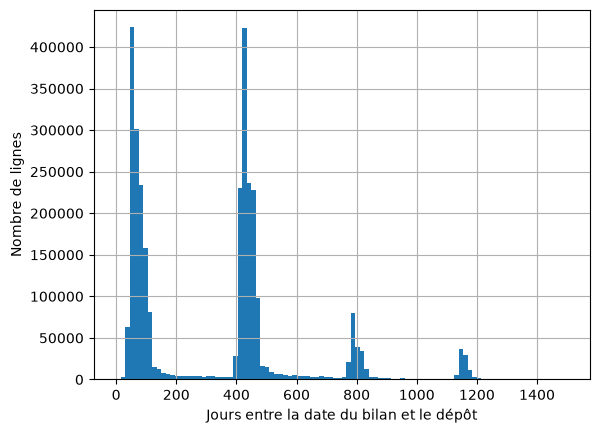

In [7]:
ecart = (df["filed"] - df["end"]).dt.days
print(ecart.quantile([0.01, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

import matplotlib.pyplot as plt
ecart[(ecart >= 0) & (ecart <= 1500)].hist(bins=100)
plt.xlabel("Jours entre la date du bilan et le dépôt"); plt.ylabel("Nombre de lignes")
plt.show()

**Constat : 4 pics**, chacun correspond à un tableau du 10-K.

| Pic | Écart | Origine | Gardé ? |
|---|---|---|---|
| 1 | ~70 j | bilan de l'année (déposé 2-3 mois après la clôture) | Oui |
| 2 | ~430 j | comparatif N-1 dans le bilan | Oui |
| 3 | ~790 j | flux de trésorerie / capitaux propres (N-2) | Non |
| 4 | ~1 150 j | capitaux propres (N-3) | Non |

**Décision :** garder **0 ≤ écart ≤ 550 jours** (coupure dans le creux entre les pics 2 et 3).
Ce filtre élimine aussi les dates futures et les dates aberrantes.

In [11]:
ecart = (df["filed"] - df["end"]).dt.days
for seuil in [500, 550, 600, 650, 700]:
    garde = (ecart >= 0) & (ecart <= seuil)
    print(f"seuil {seuil} j : {garde.mean():.1%} des lignes gardées")

seuil 500 j : 86.9% des lignes gardées
seuil 550 j : 87.8% des lignes gardées
seuil 600 j : 88.4% des lignes gardées
seuil 650 j : 88.8% des lignes gardées
seuil 700 j : 89.2% des lignes gardées


**Analyse de sensibilité :** entre 500 et 700 jours, la part de lignes gardées varie de 86,9 % à 89,2 % (2,3 points).
Le seuil tombe dans une zone presque vide → le choix exact de 550 j a peu d'impact.

## 3. Valeurs déclarées plusieurs fois et corrections (restatements)

In [10]:
d = df[(ecart >= 0) & (ecart <= 550)]
g = d.groupby(["cik", "concept", "end"])["val"]
print("Dates déclarées plusieurs fois :", round((g.size() > 1).mean(), 3))
print("…dont la valeur a changé      :", round((g.nunique() > 1).mean(), 3))

Dates déclarées plusieurs fois : 0.703
…dont la valeur a changé      : 0.058


**Constat :** 70,3 % des valeurs sont déclarées dans plusieurs rapports (comparatif N-1).
Parmi elles, ~8,3 % ont été corrigées (5,8 % de l'ensemble).
**Décision :** garder la première valeur publiée (point-in-time) pour éviter le look-ahead bias.
Pourquoi c’est important : ça justifie avec des chiffres le choix de prendre la première valeur publiée. Si on prenait la valeur corrigée, environ 8 % des bilans contiendraient une information que la banque n’avait pas au moment de sa décision (look-ahead bias).

## 4. Couverture des postes

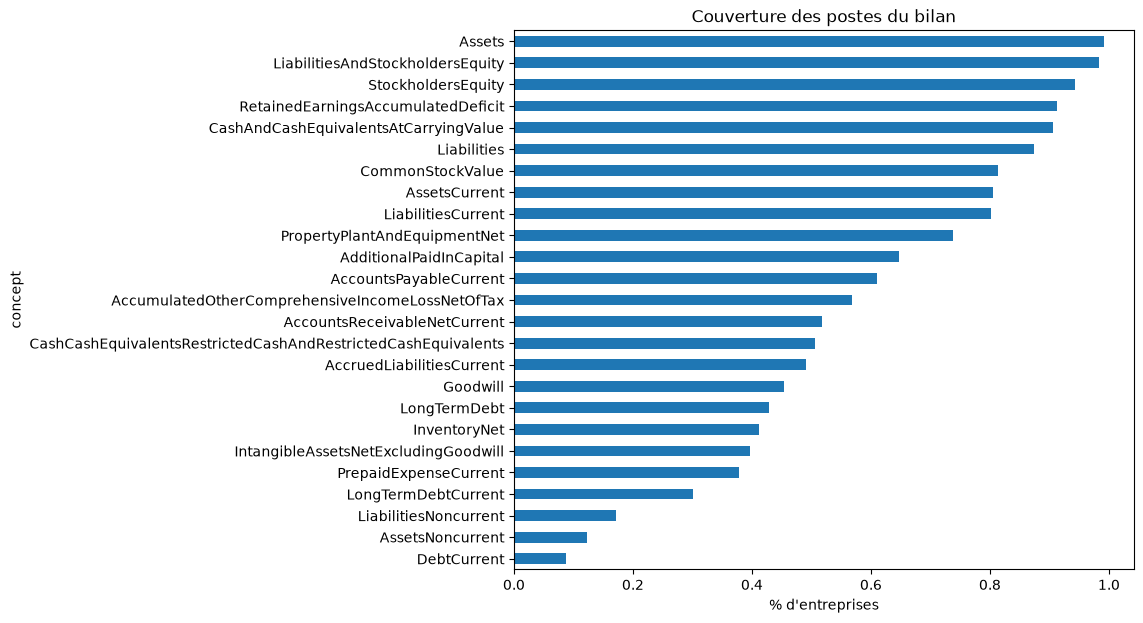

In [12]:
# Couverture des postes : % d'entreprises qui déclarent chaque concept
couv = df.groupby("concept")["cik"].nunique() / df["cik"].nunique()
couv.sort_values().plot.barh(figsize=(8, 7))
plt.xlabel("% d'entreprises"); plt.title("Couverture des postes du bilan"); plt.show()

**Constat :**
- Très bien couverts (≥ 85 %) : `Assets` (~99 %), `LiabilitiesAndStockholdersEquity`, `StockholdersEquity`,
  `RetainedEarnings`, `Cash`, `Liabilities`.
- Bien couverts (~75-80 %) : `AssetsCurrent`, `LiabilitiesCurrent`, `PropertyPlantAndEquipmentNet`.
- Peu couverts : `DebtCurrent` (~9 %), `AssetsNoncurrent` (~12 %), `LiabilitiesNoncurrent` (~17 %),
  `LongTermDebtCurrent` (~30 %), `LongTermDebt` (~43 %) — la dette est déclarée sous des concepts XBRL variés.

**Décisions :**
- Les 6 postes cibles (actifs, passifs, trésorerie, capitaux propres, actifs et passifs courants) sont tous couverts à ≥ 80 %.
- Les postes non courants se déduisent : `AssetsNoncurrent = Assets − AssetsCurrent`,
  `LiabilitiesNoncurrent = Liabilities − LiabilitiesCurrent`.
- Les concepts de dette, trop lacunaires, ne seront pas des features principales (on utilisera `Liabilities`).

## 5. Profondeur historique par entreprise

count    13962.000000
mean         7.832044
std          5.399697
min          1.000000
25%          3.000000
50%          6.000000
75%         12.000000
max         58.000000
Name: end, dtype: float64


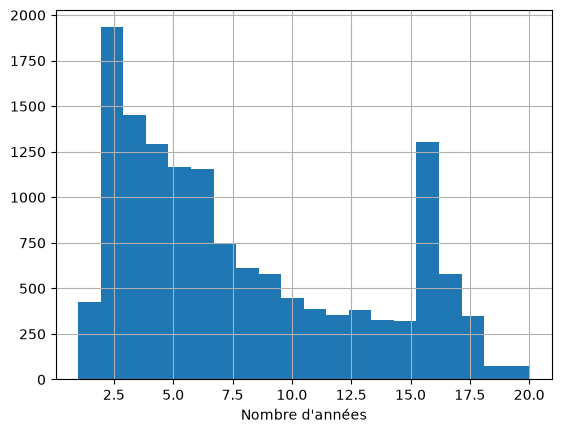

In [13]:
# Nombre d'années de bilan par entreprise (après filtre des dates)
d = df[((df.filed - df.end).dt.days.between(0, 550)) & (df.concept == "Assets")]
n_annees = d.groupby("cik")["end"].nunique()
print(n_annees.describe())
n_annees.clip(upper=20).hist(bins=20); plt.xlabel("Nombre d'années"); plt.show()

**Constat :** médiane = 6 bilans par entreprise, 25 % en ont ≤ 3, 25 % en ont ≥ 12.
**Anomalie :** maximum = 58 dates pour ~17 ans de données → certaines entreprises ont **plusieurs clôtures par an**
(changement de date de clôture, exercices courts). À contrôler dans `build_wide` avec l'écart entre deux clôtures (`days_since_prev`).

In [16]:
print(n_annees.value_counts().sort_index().head(5))   # comptes exacts pour 1, 2, 3... ans
print("Entreprises utilisables (≥ 3 ans) :", (n_annees >= 3).sum(),
      f"({(n_annees >= 3).mean():.1%})")

end
1     426
2    1932
3    1450
4    1295
5    1168
Name: count, dtype: int64
Entreprises utilisables (≥ 3 ans) : 11604 (83.1%)


**Constat :** distribution bimodale. Pic à 2-3 ans (entrées/sorties de cote récentes)
et pic à ~16 ans (entreprises présentes sur toute la période XBRL, 2009 → aujourd'hui).
**Décision :** garder les entreprises avec ≥ 3 bilans (nécessaire pour t-1, t, t+1).
**Limite :** biais du survivant : les entreprises qui disparaissent tôt incluent
des faillites, justement les cas risqués pour une banque.

## 6. Couverture temporelle

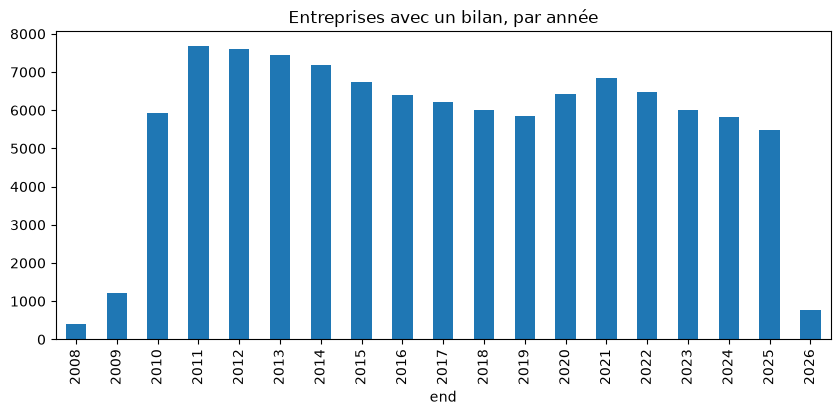

In [14]:
# Nombre d'entreprises par année
d.groupby(d["end"].dt.year)["cik"].nunique().plot.bar(figsize=(10, 4))
plt.title("Entreprises avec un bilan, par année"); plt.show()

**Constat :**
- 2008-2011 : montée en charge de l'obligation XBRL (par vagues : grandes entreprises en 2009 → toutes en 2011).
  Les bilans 2008 sont les comparatifs des premiers rapports XBRL.
- 2011-2019 : baisse du nombre d'entreprises cotées (~7 700 → ~5 850).
- 2020-2021 : remontée (boom IPO/SPAC), puis baisse.
- 2026 : année incomplète (rapports pas encore déposés).
**Décisions :**
- Les bilans 2025 n'ont pas encore de t+1 → utilisables seulement en prédiction.
- Split temporel : train ≤ 2019, validation 2020-2021, test 2022-2024 (à confirmer).

## 7. Valeurs négatives et nulles

In [15]:
# Valeurs négatives : normales pour certains postes, suspectes pour d'autres
(df.assign(neg=df.val < 0).groupby("concept")["neg"].mean()
   .sort_values(ascending=False).head(10))

concept
AccumulatedOtherComprehensiveIncomeLossNetOfTax    0.677061
RetainedEarningsAccumulatedDeficit                 0.580639
StockholdersEquity                                 0.224875
AdditionalPaidInCapital                            0.013714
DebtCurrent                                        0.012088
LongTermDebtCurrent                                0.008879
LongTermDebt                                       0.000639
CashAndCashEquivalentsAtCarryingValue              0.000286
CommonStockValue                                   0.000267
LiabilitiesAndStockholdersEquity                   0.000243
Name: neg, dtype: float64

In [17]:
(df.assign(zero=df.val == 0).groupby("concept")["zero"].mean()
   .sort_values(ascending=False).head(8))

concept
LongTermDebtCurrent                      0.090754
DebtCurrent                              0.041917
CommonStockValue                         0.027467
PrepaidExpenseCurrent                    0.026051
Goodwill                                 0.023338
LongTermDebt                             0.022505
LiabilitiesNoncurrent                    0.021181
CashAndCashEquivalentsAtCarryingValue    0.019186
Name: zero, dtype: float64

**Constat :**
- Négatifs normaux : AOCI (68 %), RetainedEarnings (58 % = déficit accumulé), StockholdersEquity (22,5 %).
- Négatifs impossibles (dette, cash, capital) : < 1,5 % → erreurs de signe.
- Assets : quasiment jamais négatif.
**Décisions :**
- Négatifs impossibles → NaN.
- Capitaux propres : cible = (E_t+1 − E_t) / Assets_t (le log est impossible si E ≤ 0).
- Postes positifs : cible = log(X_t+1) − log(X_t).
- Feature à créer : RetainedEarnings / Assets (signal de risque).

**Constat (zéros) :** dette à court terme (9 % et 4 %), capital social (2,7 %), goodwill (2,3 %), trésorerie (1,9 %).
Ce sont en général de **vrais zéros** (pas d'échéance de dette, pas d'acquisition…).

**Décisions :**
- Garder les zéros : un zéro déclaré ≠ une valeur manquante.
- Trésorerie et capitaux propres : cible = variation / `Assets_t` (le log est impossible si la valeur est ≤ 0).

## Synthèse : règles de nettoyage retenues (implémentées dans `src/build_wide.py`)

| # | Règle | Justification |
|---|---|---|
| 1 | Garder 0 ≤ `filed − end` ≤ 550 j | 4 pics : seuls les pics 1-2 viennent du bilan ; supprime dates futures et aberrantes |
| 2 | Pour chaque (cik, poste, date) : **première valeur publiée** | ~8 % des comparatifs sont corrigés → éviter le look-ahead bias |
| 3 | Négatifs impossibles (actifs, dette, trésorerie…) → NaN | erreurs de signe (< 1,5 %) |
| 4 | Garder les zéros | zéro déclaré ≠ manquant |
| 5 | Ne garder que les dates où `Assets` est déclaré | vraies dates de clôture de bilan |
| 6 | Reconstruire `Liabilities` manquant par l'identité comptable | `Liabilities` moins couvert que `Assets` |
| 7 | Dater avec `end`, jamais avec `fy` | `fy` = exercice du rapport |
| 8 | ≥ 3 bilans par entreprise pour la modélisation | t-1, t, t+1 → 11 604 entreprises (83,1 %) |

**Choix des cibles :** variation de log pour les postes positifs ; variation / `Assets_t` pour la trésorerie et les capitaux propres.

**Limites :** biais du survivant (les entreprises qui disparaissent incluent des faillites) ;
2026 incomplète ; dette mal couverte en XBRL.

**Chiffres clés :** 3,0 M valeurs · 14 081 entreprises · 25 postes · 70,3 % de valeurs déclarées plusieurs fois ·
5,8 % corrigées · 11 604 entreprises utilisables.